# ContinuityGuard / RASCALS
## 01 - Current frozen model review

Actual fitting, validation selection and the first fresh V5 evaluation ran in `06_detector_upgrade.executed.ipynb`. V3 training outputs are retained under `history/v3`. This review loads the frozen artifacts without changing them. Repeating final seeds is reproduction, not another independent evaluation.

In [1]:
from pathlib import Path
import os, sys, platform, json
ROOT = Path.cwd()
if not (ROOT / 'continuityguard').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'continuityguard').is_dir(), 'Open this notebook from the project notebooks folder'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('Team: RASCALS')
print('Architecture:', platform.machine())
print('Python:', platform.python_version())
print('Project:', ROOT)
assert platform.machine() == 's390x', 'This submission notebook is intended to run on LinuxONE'


Team: RASCALS
Architecture: s390x
Python: 3.12.15
Project: /home/ibm-user/shared/continuityguard


In [2]:
from continuityguard.models import ModelBundle
bundle=ModelBundle(ROOT/'artifacts')
report=json.loads((ROOT/'artifacts/report.json').read_text())
freeze=json.loads((ROOT/'artifacts/freeze.json').read_text())
assert freeze['model_sha256']==bundle.manifest['sha256']
print('Frozen model:',bundle.manifest)
print('Policy:',bundle.state['policy'])
print('Original training/evaluation notebook: 06_detector_upgrade.executed.ipynb')
print('Frozen before final evaluation:',freeze)


Frozen model: {'version': 'cg-2026-10-17-v5', 'trained_utc': '2026-10-17T13:07:45.438758+00:00', 'architecture': 's390x', 'model': 'logistic_C0.1', 'forecast_horizon_seconds': 60, 'feature_count': 26, 'sha256': 'ca4328b8ed2099ea4a007e75e626a4a6db63344d5c492c344733ac6f9f4d65b5', 'packages': {'numpy': '2.0.2', 'scikit-learn': '1.9.0', 'scipy': '1.13.1', 'joblib': '1.6.0'}}
Policy: {'mode': 'repeat_filtered', 'forecast_threshold': 1.01, 'standalone_forecast_paging': False, 'warning_gate': 0.97, 'trend_guard': False, 'novelty_threshold': 0.5967641153063866, 'novelty_quantile': 0.995, 'refresh_seconds': 60}
Original training/evaluation notebook: 06_detector_upgrade.executed.ipynb
Frozen before final evaluation: {'frozen_utc': '2026-10-17T13:07:45.446879+00:00', 'model_sha256': 'ca4328b8ed2099ea4a007e75e626a4a6db63344d5c492c344733ac6f9f4d65b5', 'policy': {'mode': 'repeat_filtered', 'forecast_threshold': 1.01, 'standalone_forecast_paging': False, 'warning_gate': 0.97, 'trend_guard': False, 'n

In [3]:
import pandas as pd
from IPython.display import display,Image
columns=['incidents','early_warning_recall','incident_precision','median_early_lead_seconds','late_detections','missed']
display(pd.DataFrame(report['systems']).T[columns])
print('Paired whole-run uncertainty:',report['paired_bootstrap'])
print('Model comparison on validation:',report['candidate_models'])


,incidents,early_warning_recall,incident_precision,median_early_lead_seconds,late_detections,missed
Static thresholds,135,0.962963,0.435065,11.0,4,1
Robust statistics,135,0.985185,0.11157,26.0,2,0
Isolation Forest,135,0.992593,0.14301,35.5,0,1
ContinuityGuard,135,0.962963,0.452703,11.0,4,1


Paired whole-run uncertainty: {'unit': 'whole run; paired detector differences; simulator-conditional', 'replicates': 500, 'early_recall_delta_95': [0.0, 0.0], 'precision_delta_95': [0.006298946269637273, 0.03154657913211283]}
Model comparison on validation: [{'name': 'logistic_C0.1', 'validation_pr_auc': 0.8656324872299803, 'validation_brier': 0.013540124520659447, 'fit_seconds': 0.775}, {'name': 'logistic_C1', 'validation_pr_auc': 0.8681711668603427, 'validation_brier': 0.013399910181760788, 'fit_seconds': 1.094}, {'name': 'boosted_trees_7_leaves', 'validation_pr_auc': 0.9174782954113465, 'validation_brier': 0.010644545716599865, 'fit_seconds': 3.971}, {'name': 'boosted_trees_15_leaves', 'validation_pr_auc': 0.9241261839231664, 'validation_brier': 0.010076765729317578, 'fit_seconds': 4.603}, {'name': 'boosted_trees_31_leaves', 'validation_pr_auc': 0.9259252614998823, 'validation_brier': 0.009867404625050652, 'fit_seconds': 5.153}]


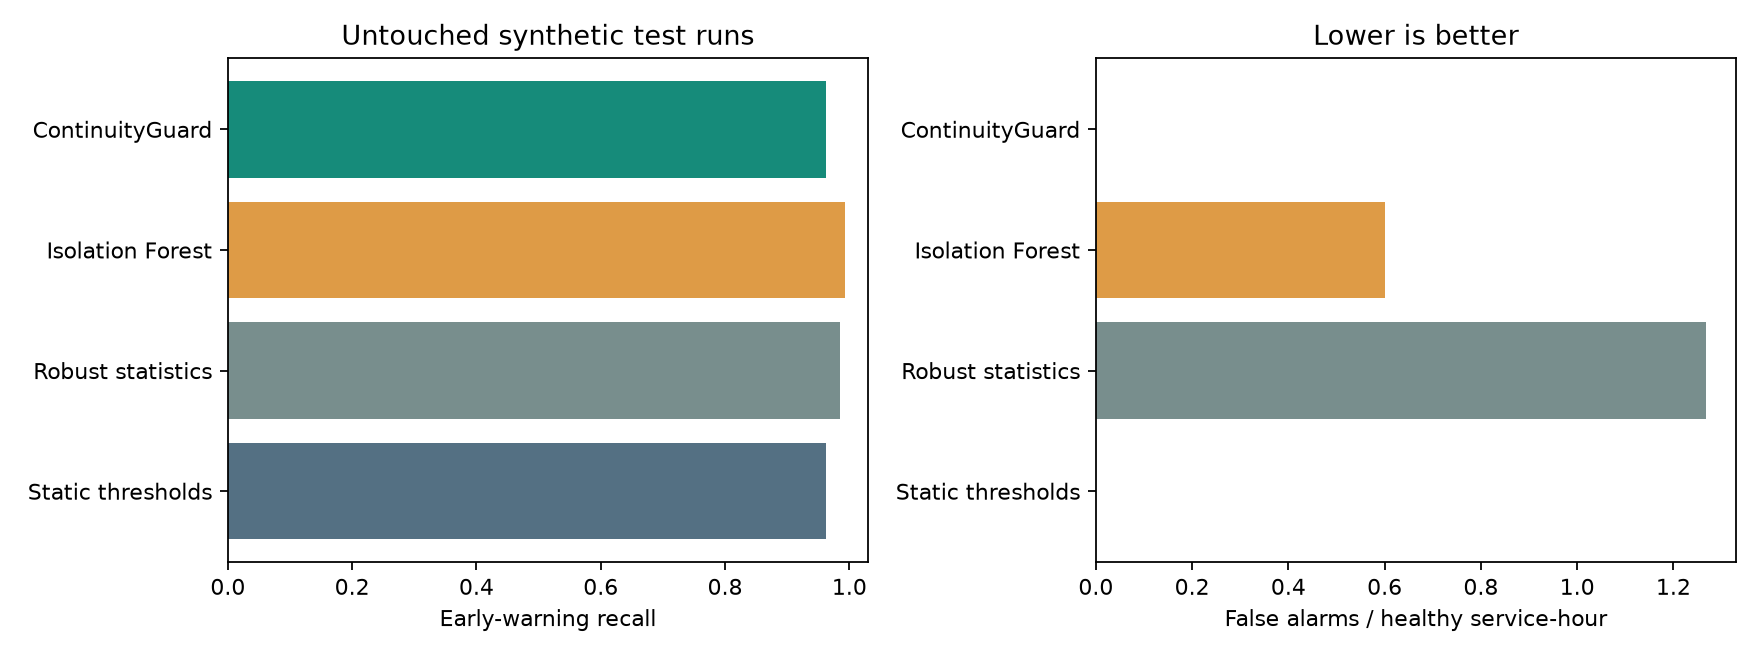

Split sizes: {'training_runs': 240, 'calibration_runs': 60, 'validation_runs': 120, 'test_runs': 180, 'unseen_abrupt_runs': 12, 'no_shared_seeds': True, 'seconds_per_run': 300, 'forecast_training_rows': 212913}
Method: {'slo': 'p95 >1000 ms or failures/requests >0.10, sustained for three 1-second windows', 'persistence': 'Every detector uses 3-of-5 persistence, 30-second cooldown and a 60-second persistent-episode recheck. No past alert can suppress notifications forever.', 'matching': 'one alert per incident, from 60 seconds before onset through 15 seconds after incident end', 'selection': 'Prefer validation precision and early recall both >= corrected static baseline; maximize 0.65 early recall + 0.35 precision with healthy false-alarm penalty; report if no strict improvement.', 'development_history': 'v1/v2/v3/v4 tests were inspected development history. V4 initial-warning filtering traded recall for precision and was rejected for deployment. V5 preserves first warnings; its fresh f

In [4]:
display(Image(filename=str(ROOT/'artifacts/benchmark.png')))
print('Split sizes:',report['split'])
print('Method:',report['method'])
print('Scope:',report['scope'])